# Head Motion and Activation Analysis
Visualisations: FD distributions per task, activation distributions per task and cope, and FD vs activation scatterplots.
Oasis cope4 and cope5 are handled separately throughout.

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from scipy import stats

BASE = '/path/to/project'

# ── Load data ──────────────────────────────────────────────────────────────────
fd_df      = pd.read_csv(os.path.join(BASE, 'mean_fd.csv'))
mean_z_df  = pd.read_csv(os.path.join(BASE, 'mean_z.csv'))
top1pct_df = pd.read_csv(os.path.join(BASE, 'mean_top1pct_z.csv'))
nvox_df    = pd.read_csv(os.path.join(BASE, 'n_suprathreshold.csv'))

print('FD columns:      ', fd_df.columns.tolist())
print('Mean Z columns:  ', mean_z_df.columns.tolist())
print('Top1pct columns: ', top1pct_df.columns.tolist())
print('Nvox columns:    ', nvox_df.columns.tolist())

FD columns:       ['subject', 'subject_id', 'session', 'session_id', 'task', 'mean_fd', 'median_fd', 'max_fd', 'pct_fd_gt_0.2', 'pct_fd_gt_0.5', 'n_volumes', 'n_fd_missing', 'tsv_file']
Mean Z columns:   ['subject', 'session', 'task', 'pipeline', 'cope', 'mean_z']
Top1pct columns:  ['subject', 'session', 'task', 'pipeline', 'cope', 'mean_top1pct_z']
Nvox columns:     ['subject', 'session', 'task', 'pipeline', 'cope', 'n_suprathreshold']


In [2]:
# ── Standardise FD ─────────────────────────────────────────────────────────────
fd_slim = fd_df[['subject', 'session', 'task', 'mean_fd']].copy()

# ── Merge FD into activation dataframes ───────────────────────────────────────
# Keep cope column so oasis cope4 and cope5 stay as separate rows
def merge_fd(act_df, fd_slim, value_col):
    merged = act_df.merge(fd_slim, on=['subject', 'session', 'task'], how='inner')
    merged = merged.dropna(subset=[value_col, 'mean_fd'])
    return merged

mz_fd = merge_fd(mean_z_df,  fd_slim, 'mean_z')
tp_fd = merge_fd(top1pct_df, fd_slim, 'mean_top1pct_z')
nv_fd = merge_fd(nvox_df,    fd_slim, 'n_suprathreshold')

# ── Define plot groups ─────────────────────────────────────────────────────────
# Each entry: (label for plot, task filter, cope filter or None)
# Non-oasis tasks have one cope each; oasis is split into cope4 and cope5
PLOT_GROUPS = [
    ('nback',        'nback',  None),
    ('mid',          'mid',    None),
    ('gonogo',       'gonogo', None),
    ('oasis (cope4)','oasis',  'cope4'),
    ('oasis (cope5)','oasis',  'cope5'),
]

TASKS        = sorted(fd_slim['task'].unique())
SESSION_PAL  = {'ses-1': '#2166ac', 'ses-2': '#d6604d'}
sessions     = ['ses-1', 'ses-2']
width        = 0.35
offsets      = [-width / 2, width / 2]
n_groups     = len(PLOT_GROUPS)
group_labels = [g[0] for g in PLOT_GROUPS]

def get_group_data(df, value_col, task, cope):
    """Filter dataframe to a specific task and optionally a specific cope."""
    sub = df[df['task'] == task].copy()
    if cope is not None:
        sub = sub[sub['cope'] == cope]
    return sub.dropna(subset=[value_col, 'mean_fd'])

ACTIVATION_METRICS = [
    (mz_fd,  'mean_z',           'Mean Z (suprathreshold)'),
    (tp_fd,  'mean_top1pct_z',   'Mean Top 1% Z'),
    (nv_fd,  'n_suprathreshold', 'N Suprathreshold Voxels'),
]

print(f'Plot groups: {group_labels}')
print(f'Merged mean_z rows: {len(mz_fd)}')

Plot groups: ['nback', 'mid', 'gonogo', 'oasis (cope4)', 'oasis (cope5)']
Merged mean_z rows: 3000


## 1. FD Distribution — Histogram per task
Oasis is one panel here since FD is task-level (not cope-level)

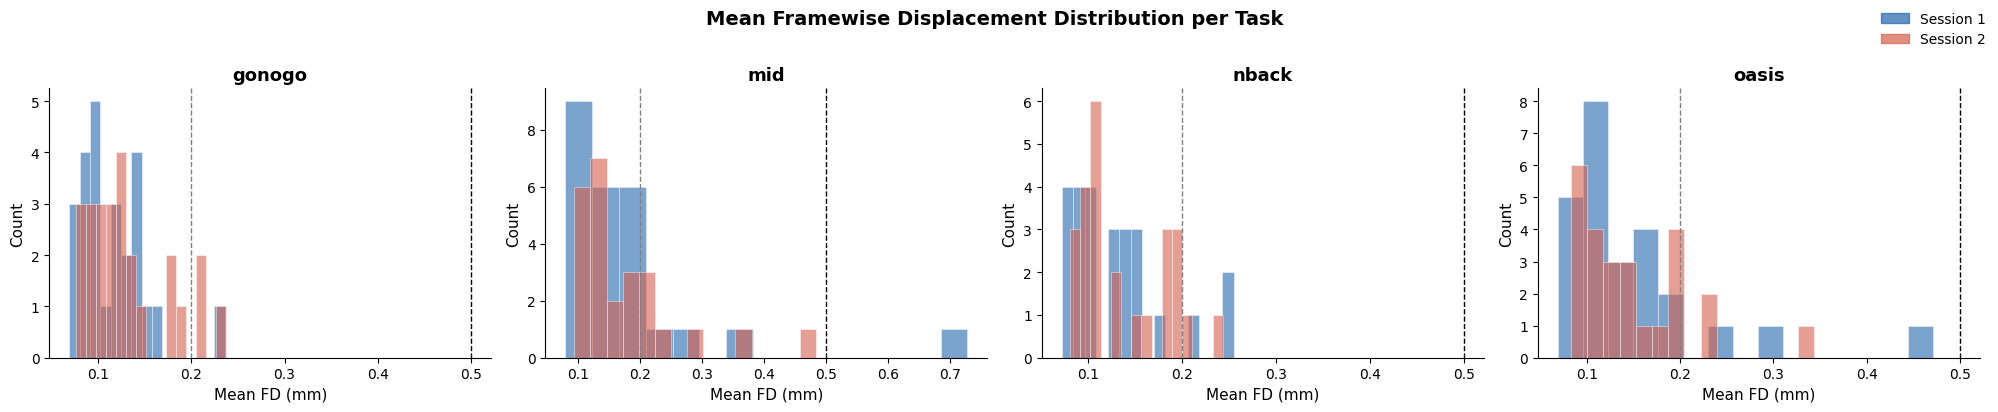

In [3]:
fig, axes = plt.subplots(1, len(TASKS), figsize=(5 * len(TASKS), 4), sharey=False)

for ax, task in zip(axes, TASKS):
    task_df = fd_slim[fd_slim['task'] == task]

    for ses, colour in SESSION_PAL.items():
        vals = task_df.loc[task_df['session'] == ses, 'mean_fd'].dropna()
        ax.hist(vals, bins=15, alpha=0.6, color=colour, label=ses,
                edgecolor='white', linewidth=0.5)

    ax.axvline(0.2, color='gray',  linestyle='--', linewidth=1)
    ax.axvline(0.5, color='black', linestyle='--', linewidth=1)
    ax.set_title(task, fontsize=13, fontweight='bold')
    ax.set_xlabel('Mean FD (mm)', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)

handles = [
    mpatches.Patch(color=SESSION_PAL['ses-1'], alpha=0.7, label='Session 1'),
    mpatches.Patch(color=SESSION_PAL['ses-2'], alpha=0.7, label='Session 2'),
]
fig.legend(handles=handles, loc='upper right', frameon=False, fontsize=10)
fig.suptitle('Mean Framewise Displacement Distribution per Task',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(BASE, 'fd_histogram_per_task.png'), dpi=150, bbox_inches='tight')
plt.show()

## 2. FD Distribution — Boxplot with jittered points per task
Oasis is one panel here since FD is task-level (not cope-level)

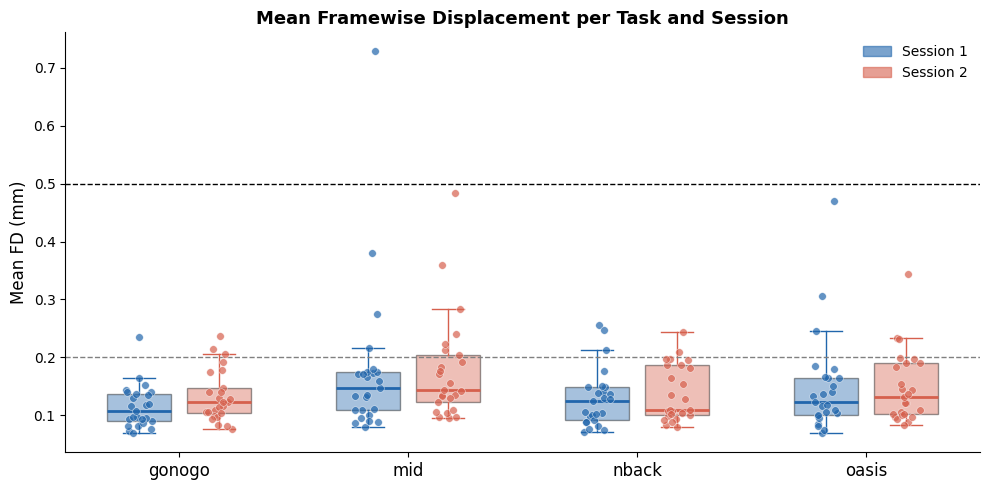

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))

for i, task in enumerate(TASKS):
    task_df = fd_slim[fd_slim['task'] == task]

    for j, ses in enumerate(sessions):
        vals   = task_df.loc[task_df['session'] == ses, 'mean_fd'].dropna().values
        x_pos  = i + offsets[j]
        colour = SESSION_PAL[ses]

        ax.boxplot(
            vals,
            positions=[x_pos],
            widths=width * 0.8,
            patch_artist=True,
            boxprops=dict(facecolor=colour, alpha=0.4),
            medianprops=dict(color=colour, linewidth=2),
            whiskerprops=dict(color=colour),
            capprops=dict(color=colour),
            flierprops=dict(marker='', linestyle='none'),
            manage_ticks=False
        )
        jitter = np.random.uniform(-0.06, 0.06, size=len(vals))
        ax.scatter(x_pos + jitter, vals, color=colour, alpha=0.7,
                   s=30, zorder=3, edgecolors='white', linewidths=0.4)

ax.axhline(0.2, color='gray',  linestyle='--', linewidth=1, label='0.2 mm')
ax.axhline(0.5, color='black', linestyle='--', linewidth=1, label='0.5 mm')
ax.set_xticks(range(len(TASKS)))
ax.set_xticklabels(TASKS, fontsize=12)
ax.set_ylabel('Mean FD (mm)', fontsize=12)
ax.set_title('Mean Framewise Displacement per Task and Session',
             fontsize=13, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)

handles = [
    mpatches.Patch(color=SESSION_PAL['ses-1'], alpha=0.6, label='Session 1'),
    mpatches.Patch(color=SESSION_PAL['ses-2'], alpha=0.6, label='Session 2'),
]
ax.legend(handles=handles, frameon=False, fontsize=10)
plt.tight_layout()
plt.savefig(os.path.join(BASE, 'fd_boxplot_per_task.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Activation distributions — Histogram per task/cope
Oasis cope4 and cope5 are separate panels

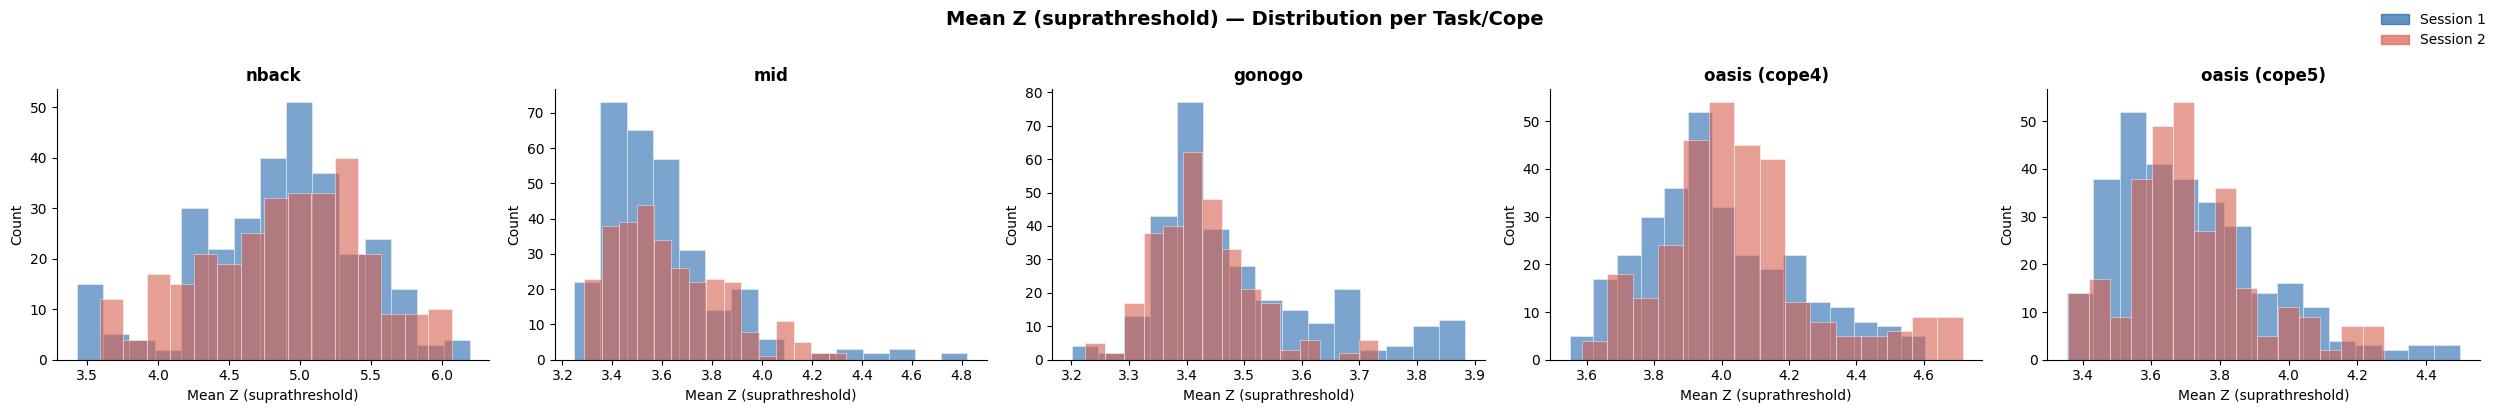

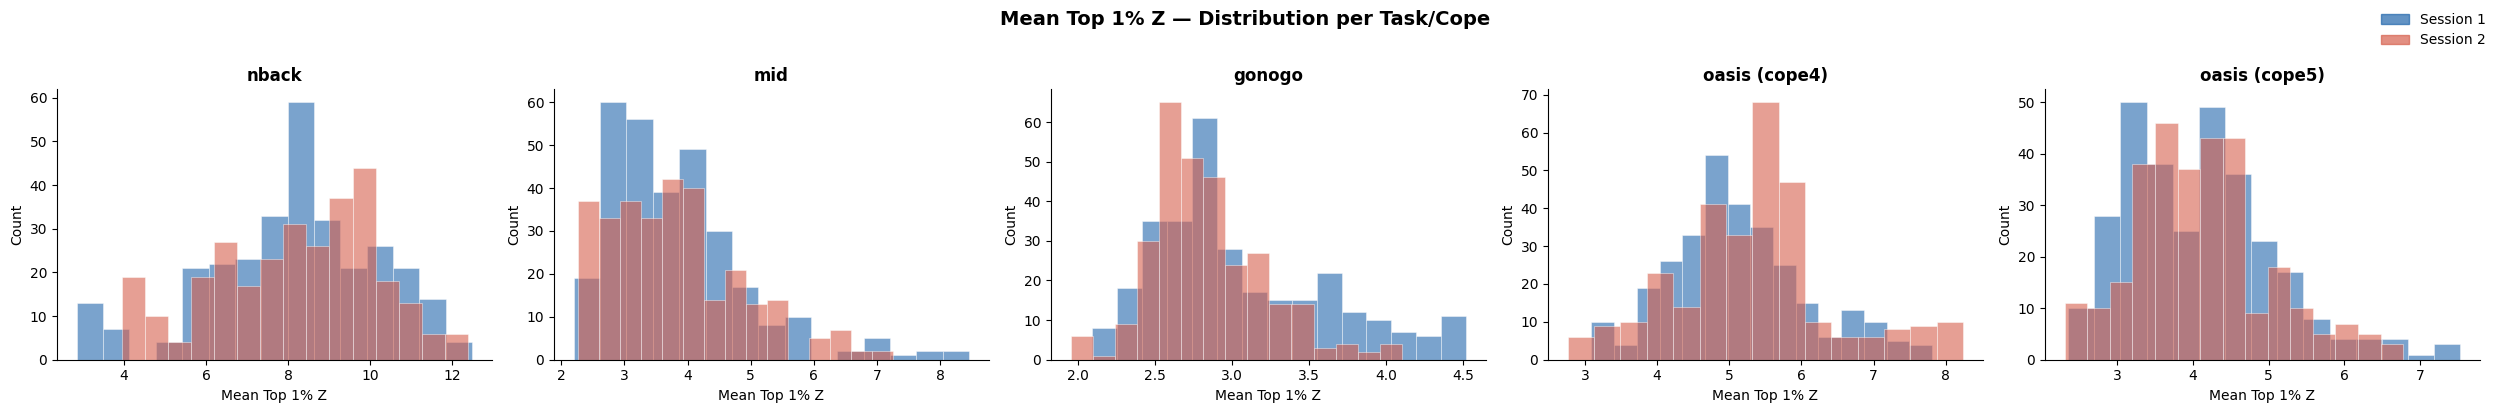

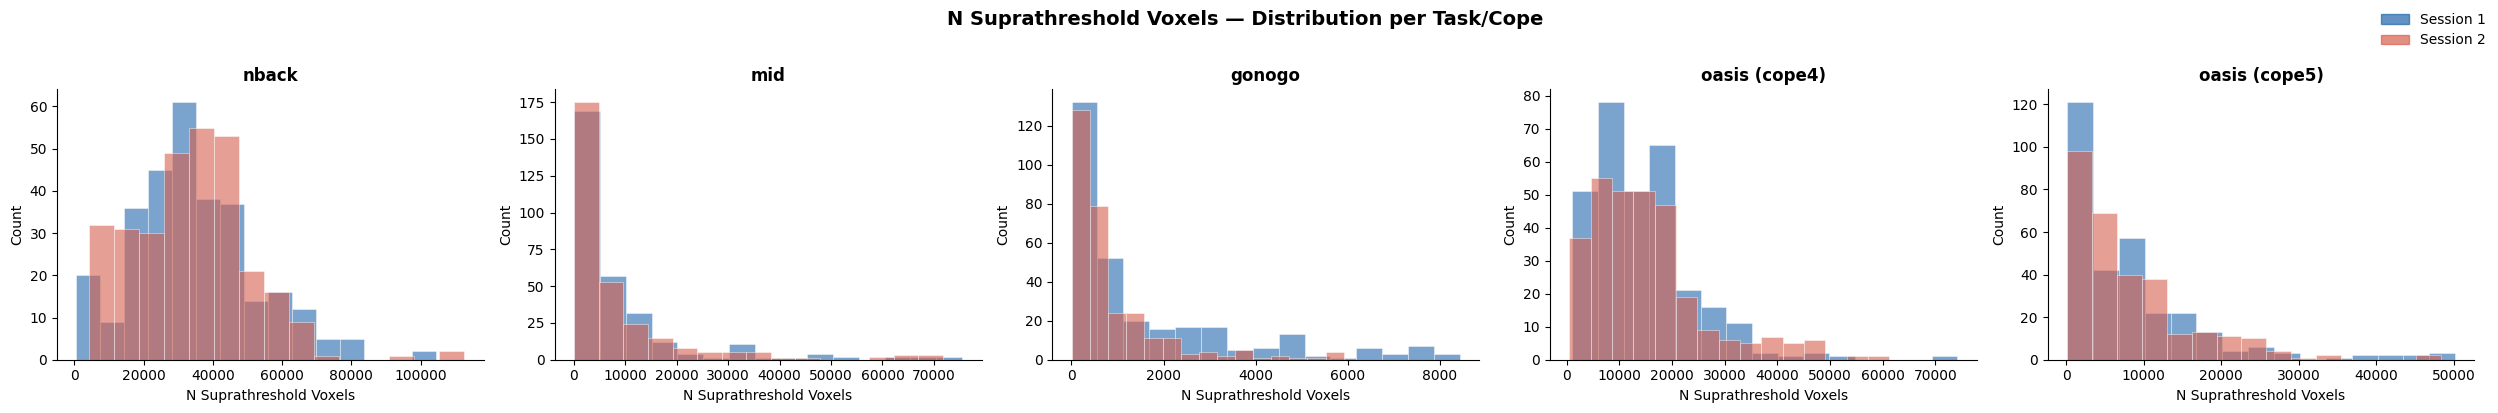

In [5]:
for df, col, label in ACTIVATION_METRICS:

    fig, axes = plt.subplots(1, n_groups, figsize=(5 * n_groups, 4), sharey=False)

    for ax, (glabel, task, cope) in zip(axes, PLOT_GROUPS):
        group_df = get_group_data(df, col, task, cope)

        for ses, colour in SESSION_PAL.items():
            vals = group_df.loc[group_df['session'] == ses, col].dropna()
            ax.hist(vals, bins=15, alpha=0.6, color=colour,
                    edgecolor='white', linewidth=0.5)

        ax.set_title(glabel, fontsize=12, fontweight='bold')
        ax.set_xlabel(label, fontsize=10)
        ax.set_ylabel('Count', fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)

    handles = [
        mpatches.Patch(color=SESSION_PAL['ses-1'], alpha=0.7, label='Session 1'),
        mpatches.Patch(color=SESSION_PAL['ses-2'], alpha=0.7, label='Session 2'),
    ]
    fig.legend(handles=handles, loc='upper right', frameon=False, fontsize=10)
    fig.suptitle(f'{label} — Distribution per Task/Cope',
                 fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, f'{col}_histogram_per_group.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 4. Activation distributions — Boxplot with jittered points per task/cope
Oasis cope4 and cope5 are separate panels

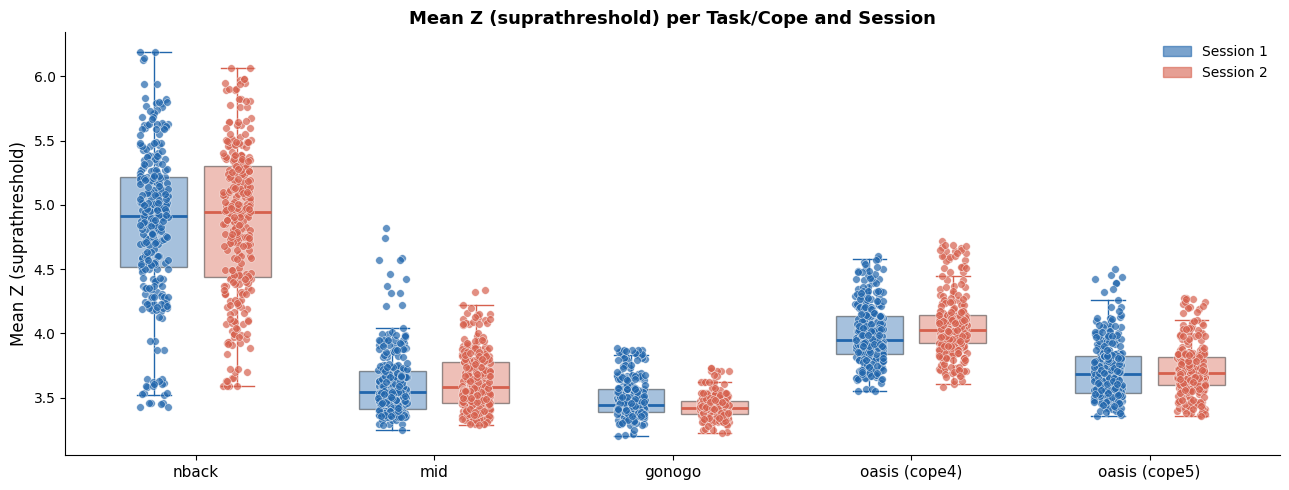

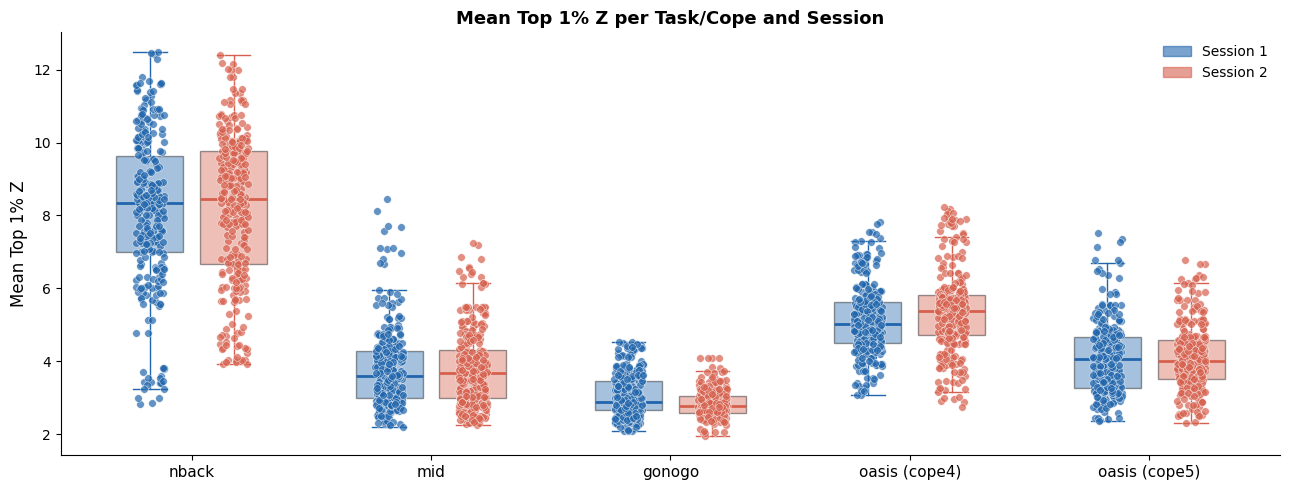

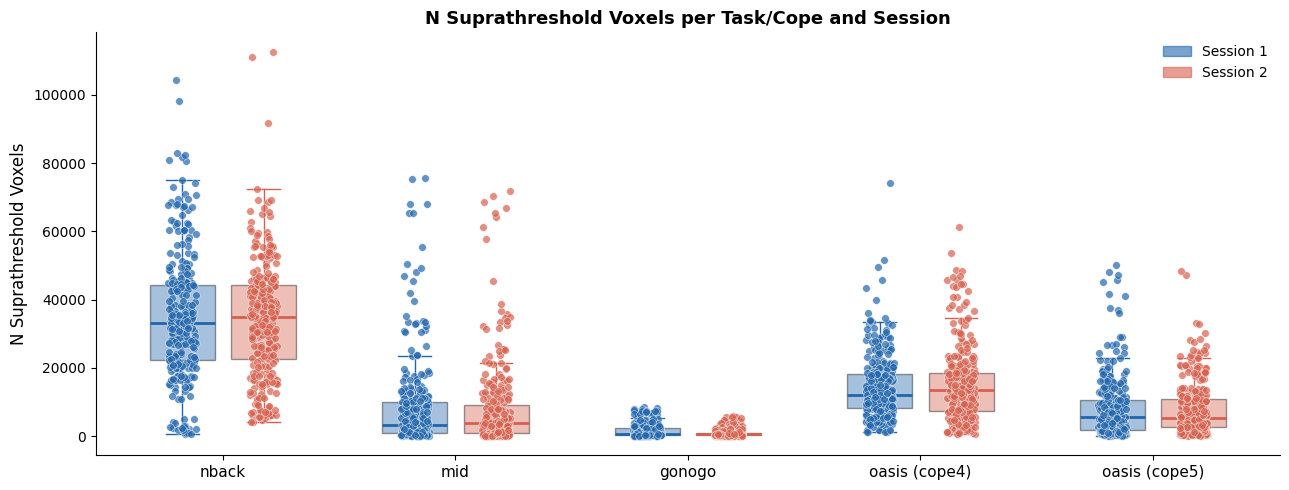

In [6]:
for df, col, label in ACTIVATION_METRICS:

    fig, ax = plt.subplots(figsize=(13, 5))

    for i, (glabel, task, cope) in enumerate(PLOT_GROUPS):
        group_df = get_group_data(df, col, task, cope)

        for j, ses in enumerate(sessions):
            vals   = group_df.loc[group_df['session'] == ses, col].dropna().values
            x_pos  = i + offsets[j]
            colour = SESSION_PAL[ses]

            ax.boxplot(
                vals,
                positions=[x_pos],
                widths=width * 0.8,
                patch_artist=True,
                boxprops=dict(facecolor=colour, alpha=0.4),
                medianprops=dict(color=colour, linewidth=2),
                whiskerprops=dict(color=colour),
                capprops=dict(color=colour),
                flierprops=dict(marker='', linestyle='none'),
                manage_ticks=False
            )
            jitter = np.random.uniform(-0.06, 0.06, size=len(vals))
            ax.scatter(x_pos + jitter, vals, color=colour, alpha=0.7,
                       s=30, zorder=3, edgecolors='white', linewidths=0.4)

    ax.set_xticks(range(n_groups))
    ax.set_xticklabels(group_labels, fontsize=11)
    ax.set_ylabel(label, fontsize=12)
    ax.set_title(f'{label} per Task/Cope and Session',
                 fontsize=13, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)

    handles = [
        mpatches.Patch(color=SESSION_PAL['ses-1'], alpha=0.6, label='Session 1'),
        mpatches.Patch(color=SESSION_PAL['ses-2'], alpha=0.6, label='Session 2'),
    ]
    ax.legend(handles=handles, frameon=False, fontsize=10)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, f'{col}_boxplot_per_group.png'), dpi=150, bbox_inches='tight')
    plt.show()

## 5. Scatterplots — Mean FD vs each activation metric
One panel per task/cope group, coloured by session, OLS trend line only.
Oasis cope4 and cope5 are separate panels.
Formal inference is in the LME cell below.

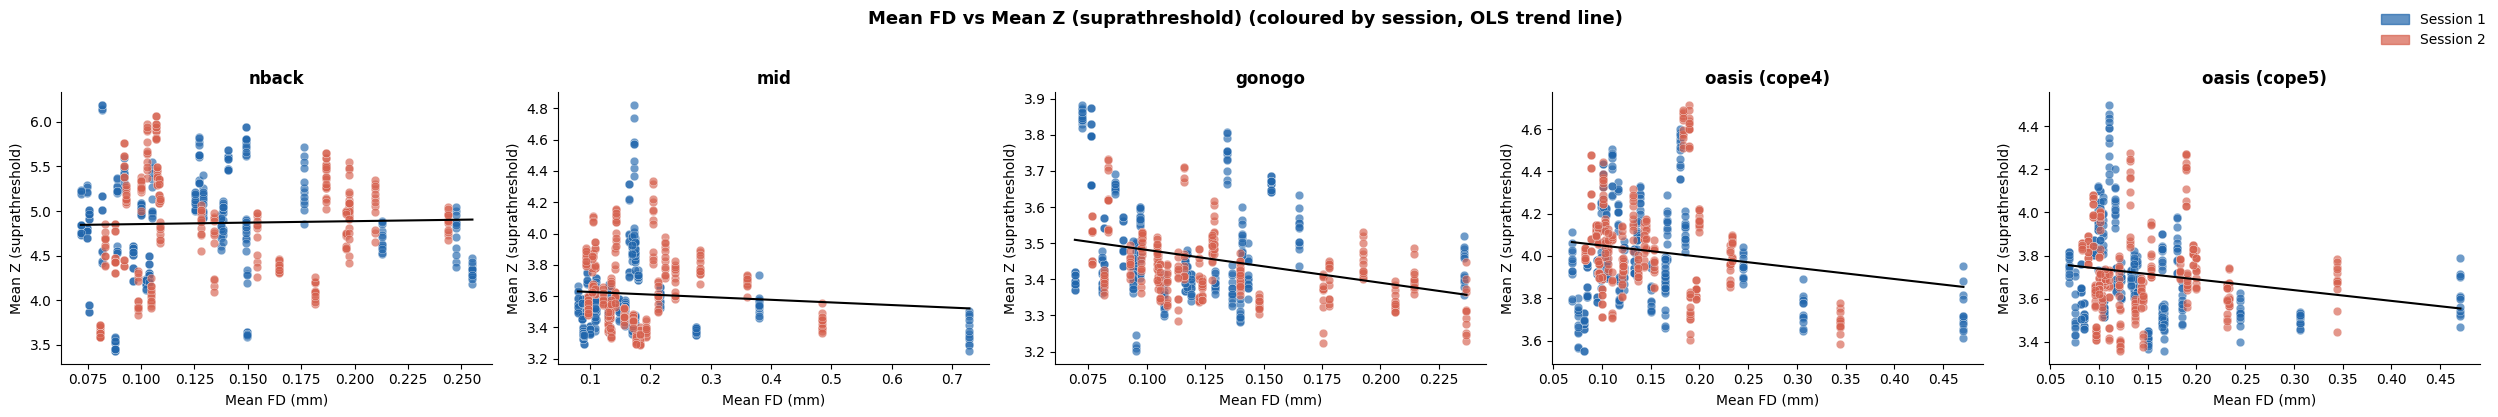

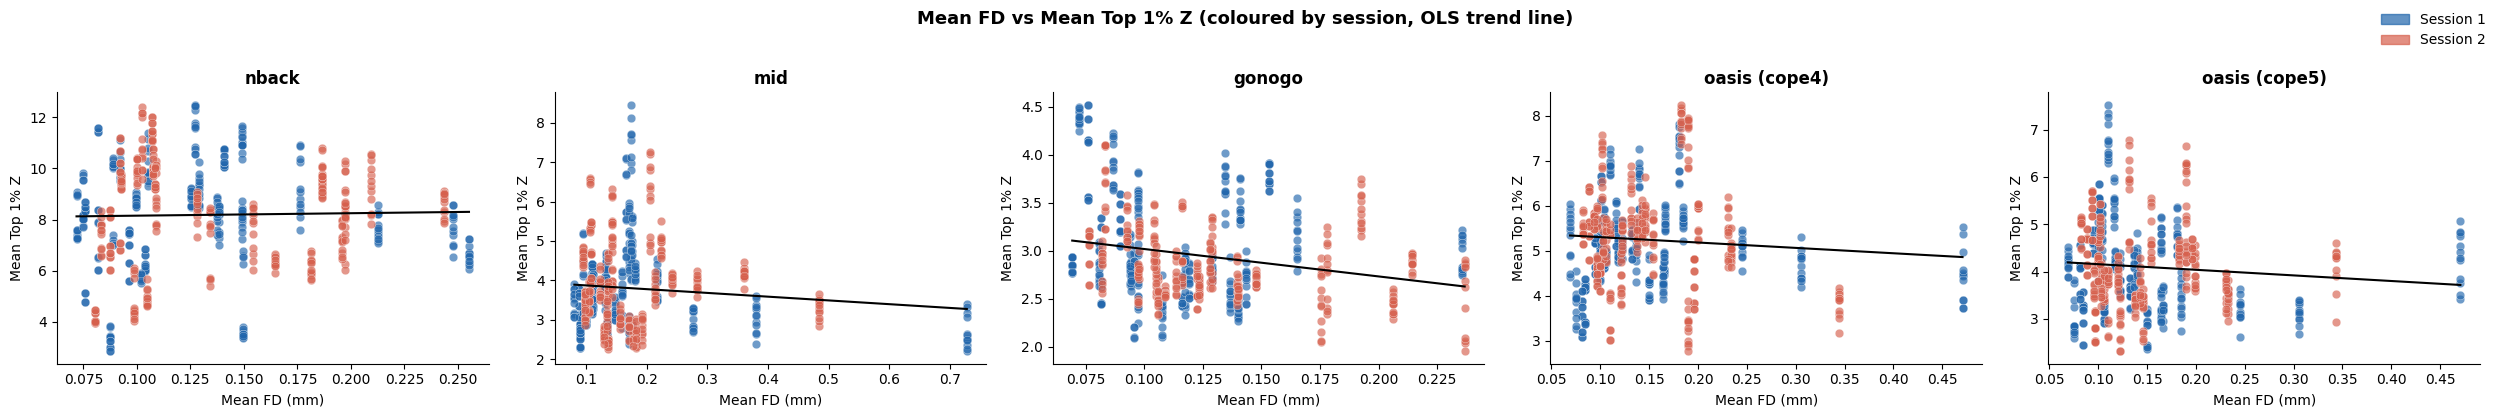

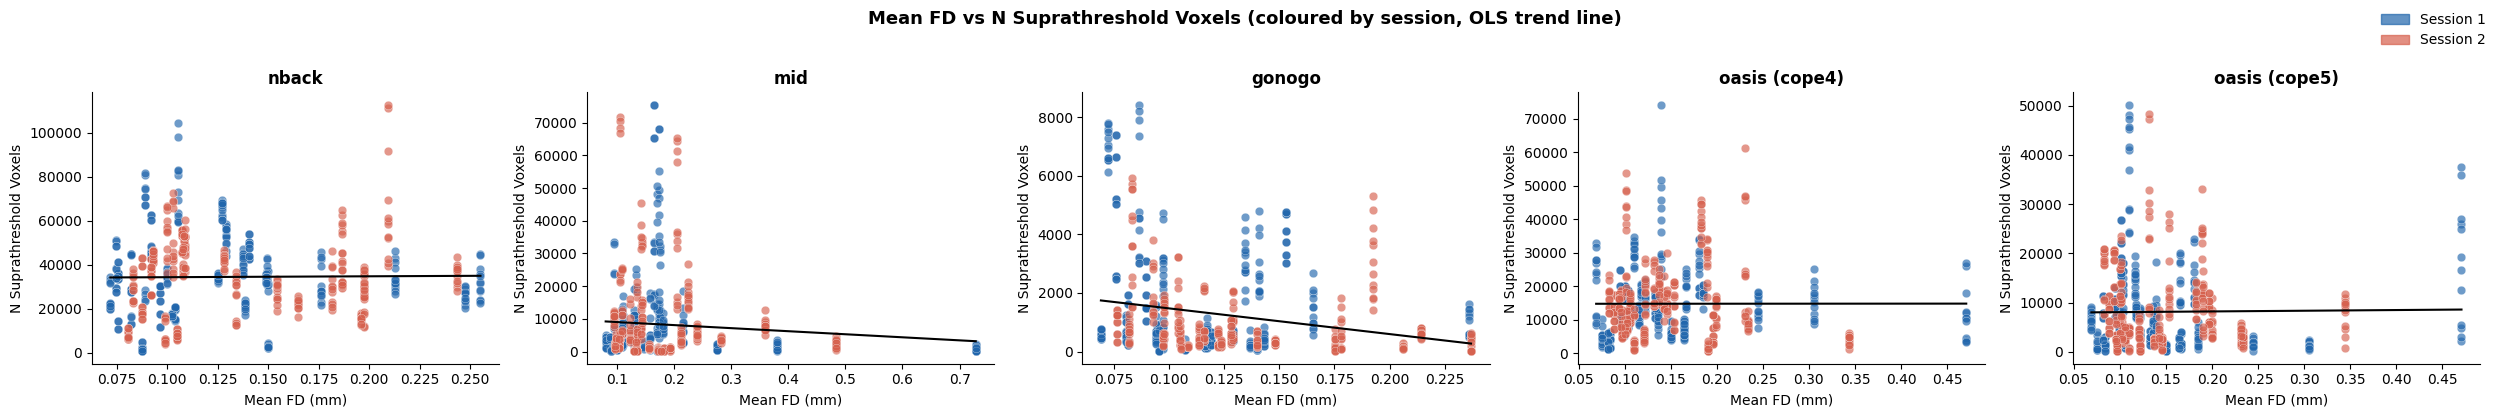

In [7]:
for df, col, label in ACTIVATION_METRICS:

    fig, axes = plt.subplots(1, n_groups, figsize=(5 * n_groups, 4), sharey=False)

    for ax, (glabel, task, cope) in zip(axes, PLOT_GROUPS):
        group_df = get_group_data(df, col, task, cope)

        for ses, colour in SESSION_PAL.items():
            sub = group_df[group_df['session'] == ses]
            ax.scatter(sub['mean_fd'], sub[col],
                       color=colour, alpha=0.65, s=38,
                       edgecolors='white', linewidths=0.3)

        # OLS trend line — pooled across sessions, visual only
        x = group_df['mean_fd'].values
        y = group_df[col].values
        if len(x) > 2:
            slope, intercept, *_ = stats.linregress(x, y)
            x_line = np.linspace(x.min(), x.max(), 100)
            ax.plot(x_line, intercept + slope * x_line,
                    color='black', linewidth=1.5, zorder=5)

        ax.set_title(glabel, fontsize=12, fontweight='bold')
        ax.set_xlabel('Mean FD (mm)', fontsize=10)
        ax.set_ylabel(label, fontsize=10)
        ax.spines[['top', 'right']].set_visible(False)

    handles = [
        mpatches.Patch(color=SESSION_PAL['ses-1'], alpha=0.7, label='Session 1'),
        mpatches.Patch(color=SESSION_PAL['ses-2'], alpha=0.7, label='Session 2'),
    ]
    fig.legend(handles=handles, loc='upper right', frameon=False, fontsize=10)
    fig.suptitle(f'Mean FD vs {label} (coloured by session, OLS trend line)',
                 fontsize=13, fontweight='bold', y=1.03)
    plt.tight_layout()
    plt.savefig(os.path.join(BASE, f'scatter_fd_vs_{col}.png'), dpi=150, bbox_inches='tight')
    plt.show()